In [11]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


IN THIS STEP OF CELL YOU SHOULD SEE THE KAGLE SETUP IS SUCESSFULL OR NOT:


In [12]:
import os     # Used to interact with files and folders in the operating system
import shutil # Used to copy, move, and manage files and folders

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!pip -q install kaggle

print("Kaggle setup complete!")

Kaggle setup complete!


Download dataset of plant:

In [13]:
!kaggle datasets download -d emmarex/plantdisease -p /content

Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:30<00:00, 22.9MB/s]



Extract the Dataset Files:

In [14]:
import zipfile
import os

zip_path = "/content/plantdisease.zip"
extract_path = "/content/plant_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path)[:10])

Dataset extracted successfully!
['plantvillage', 'PlantVillage']


Find the image folders:

In [15]:
import os

# Find folders containing plant disease categories
for root, dirs, files in os.walk("/content/plant_dataset"):
    if dirs:
        print(root, "->", len(dirs), "subfolders")

/content/plant_dataset -> 2 subfolders
/content/plant_dataset/plantvillage -> 1 subfolders
/content/plant_dataset/plantvillage/PlantVillage -> 15 subfolders
/content/plant_dataset/PlantVillage -> 15 subfolders


Check the disease categories:

In [16]:
import os

# Check the first folder
folder1 = "/content/plant_dataset/PlantVillage"

print("Disease categories:")
print(os.listdir(folder1))

Disease categories:
['Tomato_Early_blight', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Pepper__bell___Bacterial_spot', 'Tomato__Target_Spot', 'Potato___Late_blight', 'Tomato_healthy', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato__Tomato_mosaic_virus', 'Potato___Early_blight', 'Potato___healthy', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Pepper__bell___healthy', 'Tomato_Bacterial_spot', 'Tomato_Late_blight']


Count the images exist in files:

In [17]:
import os

# Folder containing the disease categories
dataset_path = "/content/plant_dataset/PlantVillage"

total_images = 0

for category in os.listdir(dataset_path):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = [
            file for file in os.listdir(category_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(category, ":", len(images), "images")
        total_images += len(images)

print("\nTotal images:", total_images)

Tomato_Early_blight : 1000 images
Tomato_Spider_mites_Two_spotted_spider_mite : 1676 images
Pepper__bell___Bacterial_spot : 997 images
Tomato__Target_Spot : 1404 images
Potato___Late_blight : 1000 images
Tomato_healthy : 1591 images
Tomato_Leaf_Mold : 952 images
Tomato_Septoria_leaf_spot : 1771 images
Tomato__Tomato_mosaic_virus : 373 images
Potato___Early_blight : 1000 images
Potato___healthy : 152 images
Tomato__Tomato_YellowLeaf__Curl_Virus : 3208 images
Pepper__bell___healthy : 1478 images
Tomato_Bacterial_spot : 2127 images
Tomato_Late_blight : 1909 images

Total images: 20638


Loading and Preprocessing the Dataset,
 and preparing for CNN training.

In [18]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create a generator to load and prepare images
datagen = ImageDataGenerator(
    rescale=1./255,          # Convert pixel values from 0-255 to 0-1
    validation_split=0.2     # Keep 20% images for validation
)

# Load training images (80% of dataset)
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

# Load validation images (20% of dataset)
val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42
)

print("Number of classes:", train_data.num_classes)
print("Training images:", train_data.samples)
print("Validation images:", val_data.samples)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
Number of classes: 15
Training images: 16516
Validation images: 4122


Building the Convolutional Neural Network(CNN) Model:

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Create the CNN model
model = Sequential()

# First convolution layer
model.add(Conv2D(32, (3, 3), activation="relu",
                 input_shape=(128, 128, 3)))
model.add(MaxPooling2D(2, 2))

# Second convolution layer
model.add(Conv2D(64, (3, 3), activation="relu"))
model.add(MaxPooling2D(2, 2))

# Third convolution layer
model.add(Conv2D(128, (3, 3), activation="relu"))
model.add(MaxPooling2D(2, 2))

# Convert feature maps into a one-dimensional array
model.add(Flatten())

# Fully connected layer
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.3))

# Output layer: 15 plant disease classes
model.add(Dense(15, activation="softmax"))

# Display the model structure
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Compiling the CNN Model:

In [20]:
# Compile the CNN model
model.compile(
    optimizer="adam",  # Helps the model learn by updating its weights
    loss="categorical_crossentropy",  # Measures prediction errors for 15 classes
    metrics=["accuracy"]  # Tracks how many predictions are correct
)
print("CNN model compiled successfully!")

CNN model compiled successfully!


Training the CNN Model:

In [21]:
history = model.fit(
    train_data,                 # Images used to train the model
    epochs=10,                  # Train the model for 10 rounds
    validation_data=val_data    # Check performance on validation images
)
print("CNN model training completed!")

Epoch 1/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 48s 75ms/step - accuracy: 0.5234 - loss: 1.4768 - val_accuracy: 0.7232 - val_loss: 0.8141
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 29s 56ms/step - accuracy: 0.7442 - loss: 0.7724 - val_accuracy: 0.8212 - val_loss: 0.5510
Epoch 3/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 28s 55ms/step - accuracy: 0.8066 - loss: 0.5781 - val_accuracy: 0.8324 - val_loss: 0.4951
Epoch 4/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 28s 54ms/step - accuracy: 0.8472 - loss: 0.4503 - val_accuracy: 0.8651 - val_loss: 0.4151
Epoch 5/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 32s 61ms/step - accuracy: 0.8774 - loss: 0.3616 - val_accuracy: 0.8782 - val_loss: 0.3485
Epoch 6/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.8942 - loss: 0.3069 - val_accuracy: 0.8712 - val_loss: 0.3954
Epoch 7/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 29s 55ms/step - accuracy: 0.9156 - loss: 0.2466 - val_accuracy: 0.8971 - val_loss: 0.3320
Epoch 8/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 27s 52ms/step - accuracy: 0.9255 - loss: 0.2193 - 

Evaluate the model:

In [22]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")


129/129 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9066 - loss: 0.2907
Validation Loss: 0.2907143533229828
Validation Accuracy: 90.65987467765808 %


In [29]:
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
model.summary()


Model input: (None, 128, 128, 3)
Model output: (None, 15)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,919,727 (37.84 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,613,152 (25.23 MB)

Saving 00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132.JPG to 00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132 (1).JPG
Image shape: (1, 128, 128, 3)


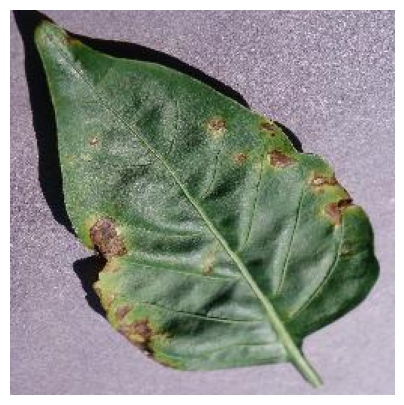

Predicted class: Tomato_Septoria_leaf_spot
Model confidence: 99.73%


In [30]:

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Upload a plant leaf image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Load image at the correct size: 128 x 128
img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img)

# Normalize pixel values
img_array = img_array / 255.0

# Add batch dimension: (1, 128, 128, 3)
img_array = np.expand_dims(img_array, axis=0)

print("Image shape:", img_array.shape)

# Predict using your trained CNN
prediction = model.predict(img_array, verbose=0)

# Get class names from the training generator
class_names = [
    name for name, index in sorted(
        train_data.class_indices.items(),
        key=lambda item: item[1]
    )
]

# Find the predicted class
class_index = np.argmax(prediction[0])
predicted_class = class_names[class_index]
confidence = prediction[0][class_index] * 100

# Display the uploaded image
plt.figure(figsize=(5, 5))
plt.imshow(load_img(image_path))
plt.axis("off")
plt.show()

# Display prediction
print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")


Predicted class: Tomato_Septoria_leaf_spot — this is the disease category your model selected.



Confidence: 99.73% — the model assigned this class a score of 99.73%.



Healthy or diseased? The model predicts a diseased tomato leaf, rather than a healthy one.

In [31]:
model.save("plant_disease_cnn.keras")
print("Plant disease model saved successfully!")

Plant disease model saved successfully!


Saving 0ed55b5a-55e6-4c9c-bce4-9eba61bc3a6b___RS_HL 9889.JPG to 0ed55b5a-55e6-4c9c-bce4-9eba61bc3a6b___RS_HL 9889.JPG


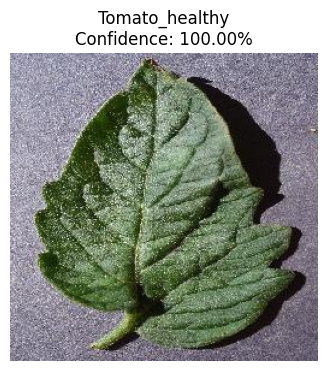

Image: 0ed55b5a-55e6-4c9c-bce4-9eba61bc3a6b___RS_HL 9889.JPG
Predicted class: Tomato_healthy
Confidence: 100.00%
----------------------------------------


In [32]:

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt
import math

# Upload multiple plant images
uploaded = files.upload()

# Get class names from your training dataset
class_names = [
    name for name, index in sorted(
        train_data.class_indices.items(),
        key=lambda item: item[1]
    )
]

# Predict each uploaded image
for image_path in uploaded.keys():

    # Load image at the correct size
    img = load_img(image_path, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Make prediction
    prediction = model.predict(img_array, verbose=0)
    class_index = np.argmax(prediction[0])
    disease = class_names[class_index]
    confidence = prediction[0][class_index] * 100

    # Display image and result
    plt.figure(figsize=(4, 4))
    plt.imshow(load_img(image_path))
    plt.axis("off")
    plt.title(f"{disease}\nConfidence: {confidence:.2f}%")
    plt.show()

    print("Image:", image_path)
    print("Predicted class:", disease)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 40)


In [36]:
!pip -q install transformers


Loading plant-leaf checker...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Plant-leaf checker is ready!


Saving 0a9b3ff4-5343-4814-ac2c-fdb3613d4e4d___Crnl_L.Mold 6559.JPG to 0a9b3ff4-5343-4814-ac2c-fdb3613d4e4d___Crnl_L.Mold 6559.JPG


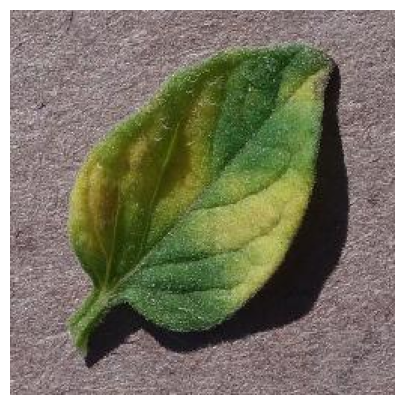

Image: 0a9b3ff4-5343-4814-ac2c-fdb3613d4e4d___Crnl_L.Mold 6559.JPG
Image checker result: a close-up photograph of a plant leaf, including a diseased leaf
Predicted plant class: Tomato_Leaf_Mold
CNN prediction score: 65.79%
---------------------------------------------


In [39]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from transformers import pipeline
from tensorflow.keras.utils import load_img, img_to_array

# 1. Load the pretrained image checker
print("Loading plant-leaf checker...")

leaf_checker = pipeline(
    "zero-shot-image-classification",
    model="openai/clip-vit-base-patch32",
    device=0 if torch.cuda.is_available() else -1
)

print("Plant-leaf checker is ready!")

# 2. Get CNN class names in the correct order
class_names = [
    name for name, index in sorted(
        train_data.class_indices.items(),
        key=lambda item: item[1]
    )
]

# 3. Labels for checking the uploaded image
candidate_labels = [
    "a close-up photograph of a plant leaf, including a diseased leaf",
    "a photograph of a mobile phone",
    "a photograph of another everyday object",
    "a photograph of a person",
    "a photograph of an animal",
    "a photograph of a car or vehicle",
    "a photograph of food",
    "a photograph of a flower without a visible leaf",
    "a photograph of a building",
    "a photograph of a landscape"
]

# 4. Upload images
uploaded = files.upload()

for image_path in uploaded.keys():

    # Display the original image
    original_image = Image.open(image_path).convert("RGB")

    plt.figure(figsize=(5, 5))
    plt.imshow(original_image)
    plt.axis("off")
    plt.show()

    # 5. Check whether the image looks like a plant leaf
    results = leaf_checker(
        original_image,
        candidate_labels=candidate_labels
    )

    best_label = results[0]["label"]
    checker_score = results[0]["score"]

    print("Image:", image_path)
    print("Image checker result:", best_label)

    # 6. Reject images that do not look like plant leaves
    if best_label != candidate_labels[0]:
        print("This image does not appear to be a plant leaf.")
        print("Please upload a plant leaf image.")

    else:
        # 7. Run your existing CNN on the accepted image
        img = load_img(image_path, target_size=(128, 128))
        img_array = img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array, verbose=0)

        class_index = np.argmax(prediction[0])
        predicted_class = class_names[class_index]
        confidence = prediction[0][class_index] * 100

        print("Predicted plant class:", predicted_class)
        print(f"CNN prediction score: {confidence:.2f}%")

    print("-" * 45)
